# Strategy Lab #2 — Mean Reversion in FX Pairs with Reinforcement Learning
**Algorithmic Token · ENTER Invest**

> ⚠️ **Experimental prototype. Educational use only — not investment advice.** See the [risk disclosure](#risk-disclosure) at the end before running anything with real money in mind.

This notebook is the hands-on companion to the Substack article
[*Strategy Lab #2: Mean Reversion in FX Pairs with RL*](https://algorithmictoken.substack.com/p/strategy-lab-2-mean-reversion-in).
It implements, end to end, a pairs-trading pipeline on two FX rates and compares:

1. a **classical z-score rule** (the baseline), against
2. a **tabular Q-learning agent** pre-trained on simulated Ornstein–Uhlenbeck (OU) paths.

**References**

- Ning, B. & Lee, K. (2024). *arXiv:2403.12180* — Empirical Mean Reversion Time (EMRT) and the RL trading agent.
- Leung, T. & Li, X. (2016). *Optimal Mean Reversion Trading* — classical OU-based baseline.
- Gatev, E., Goetzmann, W. & Rouwenhorst, K. (2006). *Pairs Trading: Performance of a Relative-Value Arbitrage Rule*.

### What you will learn
| Step | Idea | Where |
|---|---|---|
| 1 | Test a pair for cointegration and estimate the half-life of mean reversion | Phase 1 |
| 2 | Choose the hedge ratio by minimising EMRT (model-free) instead of fitting an OU model | Phase 2 |
| 3a | Trade the spread with a fixed z-score rule | Phase 3a |
| 3b | Train a Q-learning agent on simulated OU paths and trade the real spread | Phase 3b |
| 4 | Run the full backtest and plot the results | Pipeline |

### Pipeline at a glance
```
 prices ──► cointegration test ──► EMRT hedge ratio ──► spread
                (Phase 1)             (Phase 2)           │
                                                          ├──► z-score rule   (Phase 3a)
                                                          └──► Q-learning RL  (Phase 3b)
```
Formation period (2022) is used to choose the hedge ratio and spread statistics. The trading period (2023) is **out of sample**.

## 0. Setup

Run the next cell once to install dependencies (skip it if they are already installed). On Google Colab, `yfinance`, `statsmodels`, `pandas`, `numpy` and `matplotlib` are typically available, but a quick install keeps versions predictable.

In [6]:
# Uncomment to install dependencies
# %pip install -q numpy pandas yfinance statsmodels matplotlib

In [7]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint
from statsmodels.regression.linear_model import OLS
from statsmodels.tools import add_constant

# Reproducibility: the RL agent uses random exploration and random OU paths.
SEED = 42
np.random.seed(SEED)

pd.options.display.float_format = "{:,.4f}".format

## Phase 1 — Pair identification

A pair is worth trading only if a linear combination of the two prices is **stationary** — i.e. the spread keeps returning to a mean. Two ingredients:

- **Cointegration test** (`statsmodels.coint`): the null hypothesis is *no cointegration*, so a small p-value is evidence *for* a mean-reverting relationship.
- **Half-life of mean reversion**: fit an AR(1) to the spread, $\Delta s_t = \lambda\, s_{t-1} + \varepsilon_t$. If $\lambda<0$ the spread reverts, and

$$\text{half-life} = -\frac{\ln 2}{\lambda}$$

The hedge ratio $\beta$ here comes from a plain OLS regression of price 1 on price 2 and gives the *spread* $s_t = P^{(1)}_t - \beta P^{(2)}_t$.

> **Naming note.** The function is called `johansen_cointegration_test` to match the article, but `statsmodels.coint` implements the **Engle–Granger** two-step test, not Johansen's. Treat the name as legacy; swap in `statsmodels.tsa.vector_ar.vecm.coint_johansen` if you want the real thing.

In [8]:
def johansen_cointegration_test(series1: pd.Series,
                                 series2: pd.Series,
                                 significance: float = 0.05) -> dict:
    """
    Test for cointegration between two price series using statsmodels coint().
    Returns test result and half-life of mean reversion.
    """
    score, pvalue, _ = coint(series1, series2)

    # Hedge ratio via OLS
    model  = OLS(series1, add_constant(series2)).fit()
    beta   = model.params.iloc[1]
    spread = series1 - beta * series2

    # Half-life of mean reversion via AR(1) regression on spread
    spread_lag   = spread.shift(1).dropna()
    delta_spread = spread.diff().dropna()
    ar_model     = OLS(delta_spread, add_constant(spread_lag)).fit()
    lam          = ar_model.params.iloc[1]
    half_life    = -np.log(2) / lam if lam < 0 else np.inf

    return {
        "cointegrated": pvalue < significance,
        "p_value":      pvalue,
        "beta":         beta,
        "spread":       spread,
        "half_life":    half_life,
    }

## Phase 2 — Spread construction via EMRT (Ning & Lee, 2024)

Classical pairs trading fits an OU model by maximum likelihood to pick the hedge ratio. Ning & Lee propose a **model-free** alternative: choose the $\beta$ that minimises the **Empirical Mean Reversion Time (EMRT)** of $FX_1 - \beta\, FX_2$.

**Intuition.** Find the big swings in the spread (local extremes at least $C$ standard deviations away from the surrounding window), then measure how many days each one takes to cross back over the sample mean. The average of those times is the EMRT. *Lower EMRT = faster mean reversion = a better spread.*

Two functions:

1. `empirical_mean_reversion_time` — computes EMRT for one spread.
2. `find_optimal_hedge_ratio_emrt` — grid-searches $\beta$ and keeps the one with the lowest EMRT. A variance cap discards spreads that "revert" only because they are huge and noisy.

**Things to try:** change `C` (extreme-size threshold), the `step` of the grid, or `beta_range`. A finer grid is slower — each candidate scans the whole series.

In [9]:
def empirical_mean_reversion_time(spread: pd.Series,
                                   C: float = 2.0) -> float:
    """
    Compute Empirical Mean Reversion Time (EMRT) for a spread series.
    Lower EMRT = faster mean reversion = better spread candidate.

    Based on Definition 3.1 in Ning & Lee (2024), arXiv:2403.12180
    """
    s        = spread.std()
    mu_hat   = spread.mean()
    values   = spread.values
    n        = len(values)
    extremes = []

    # Identify local extremes (Fink & Gandhi, 2007 criterion)
    for m in range(1, n - 1):
        # Check for local minimum
        left_max  = max(values[max(0, m-20):m])
        right_max = max(values[m+1:min(n, m+21)])
        if (left_max - values[m] >= C * s and
                right_max - values[m] >= C * s):
            extremes.append((m, "min"))

        # Check for local maximum
        left_min  = min(values[max(0, m-20):m])
        right_min = min(values[m+1:min(n, m+21)])
        if (values[m] - left_min >= C * s and
                values[m] - right_min >= C * s):
            extremes.append((m, "max"))

    if len(extremes) < 2:
        return np.inf

    # Compute reversion times: from each extreme to next mean crossing
    reversion_times = []
    for idx, (extreme_pos, _) in enumerate(extremes):
        for future_pos in range(extreme_pos + 1, n):
            if ((values[future_pos - 1] < mu_hat <= values[future_pos]) or
                    (values[future_pos - 1] > mu_hat >= values[future_pos])):
                reversion_times.append(future_pos - extreme_pos)
                break

    return np.mean(reversion_times) if reversion_times else np.inf

In [10]:
def find_optimal_hedge_ratio_emrt(fx1: pd.Series,
                                   fx2: pd.Series,
                                   beta_range: tuple = (-3.0, 3.0),
                                   step: float = 0.05,
                                   max_variance: float = None) -> dict:
    """
    Find the hedge ratio B minimising EMRT of (FX1 - B * FX2).
    Model-free alternative to OU maximum likelihood estimation.
    """
    if max_variance is None:
        max_variance = fx1.std() ** 2 * 10  # generous default cap

    best_beta = 1.0
    best_emrt = np.inf
    betas     = np.arange(beta_range[0], beta_range[1] + step, step)

    for beta in betas:
        spread = fx1 - beta * fx2
        if spread.var() > max_variance:
            continue
        emrt = empirical_mean_reversion_time(spread)
        if emrt < best_emrt:
            best_emrt = emrt
            best_beta = beta

    spread = fx1 - best_beta * fx2
    return {
        "beta":         best_beta,
        "emrt":         best_emrt,
        "spread":       spread,
        "spread_mean":  spread.mean(),
        "spread_std":   spread.std(),
    }

## Phase 3a — Classical z-score trading rule (baseline)

The benchmark every RL strategy should have to beat. Standardise the spread with the **formation-period** mean and standard deviation (so there is no look-ahead into the trading period):

$$z_t = \frac{s_t - \mu_{\text{formation}}}{\sigma_{\text{formation}}}$$

| Condition | Action |
|---|---|
| flat and $z < -2.0$ | go **long** the spread |
| flat and $z > +2.0$ | go **short** the spread |
| long and $z > -0.5$ | exit |
| short and $z < +0.5$ | exit |

Transaction costs (`cost_bps`, default 5 bp of the spread level) are charged on every entry and exit.

> The P&L is expressed in **spread price units** per day, not as a percentage return. Keep that in mind when reading the drawdown figure later.

In [11]:
def classical_zscore_strategy(spread: pd.Series,
                               formation_mean: float,
                               formation_std: float,
                               entry_threshold: float = 2.0,
                               exit_threshold: float = 0.5,
                               cost_bps: float = 5.0) -> pd.Series:
    """
    Classical fixed-threshold mean reversion trading on z-score.
    Long when z < -entry, exit when z > -exit.
    Short when z > +entry, exit when z < +exit.
    """
    cost      = cost_bps / 10_000
    z         = (spread - formation_mean) / formation_std
    position  = 0
    pnl       = []

    for i in range(1, len(spread)):
        daily_pnl = position * (spread.iloc[i] - spread.iloc[i - 1])

        if position == 0:
            if z.iloc[i] < -entry_threshold:
                position = 1
                daily_pnl -= cost * abs(spread.iloc[i])
            elif z.iloc[i] > entry_threshold:
                position = -1
                daily_pnl -= cost * abs(spread.iloc[i])
        elif position == 1 and z.iloc[i] > -exit_threshold:
            position = 0
            daily_pnl -= cost * abs(spread.iloc[i])
        elif position == -1 and z.iloc[i] < exit_threshold:
            position = 0
            daily_pnl -= cost * abs(spread.iloc[i])

        pnl.append(daily_pnl)

    return pd.Series(pnl, index=spread.index[1:])

## Phase 3b — Q-learning RL agent (Ning & Lee, 2024)

A deliberately small, **tabular** reinforcement-learning agent — no neural networks, so every number can be inspected.

**State.** The last `lookback` (default 4) spread returns, each discretised into 4 buckets using threshold `k`:

| Return $r$ | Bucket |
|---|---|
| $r > k$ | 3 (large up) |
| $0 < r \le k$ | 2 (small up) |
| $-k < r \le 0$ | 1 (small down) |
| $r \le -k$ | 0 (large down) |

The four buckets are packed into one base-4 integer, giving $4^4 = 256$ states.

**Position.** Flat (0) or long (1). The agent is long-only on the spread.

**Actions.** `sell/close` (−1), `hold` (0), `buy/open` (+1), masked so only legal moves are chosen: flat → {hold, buy}; long → {sell, hold}.

**Learning.** Standard Q-learning with ε-greedy exploration:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\big]$$

**Why simulate?** One year of daily FX data is ~250 observations — far too few for a Q-table to converge. Following Ning & Lee, the agent is **pre-trained on thousands of simulated OU paths**:

$$dX_t = \mu(\theta - X_t)\,dt + \sigma\,dW_t$$

with $\theta$ set to the formation-period spread mean. At trade time ε = 0 (pure exploitation).

**Hyperparameters worth experimenting with:** `lookback`, `k`, `alpha`, `gamma`, `epsilon`, and the OU parameters `mu` (reversion speed) and `sigma` (noise).

In [12]:
class MeanReversionRLAgent:
    """
    Tabular Q-learning agent for mean reversion trading.
    State: Discretized z-score of the spread (valuation context)
           plus the direction of the last movement.
    Actions: {-1: sell/short/close long, 0: hold, +1: buy/long/close short}
    Positions: {0: FLAT, 1: LONG, 2: SHORT}
    """

    def __init__(self, lookback: int = 1, alpha: float = 0.1, gamma: float = 0.99, epsilon: float = 0.15):
        self.lookback   = lookback
        # State space: 6 buckets for z-score level (<-2, -2 to -0.5, -0.5 to 0, 0 to 0.5, 0.5 to 2, >2)
        # multiplied by 2 buckets for recent direction (down vs up)
        self.n_states   = 6 * 2
        # Q-table shape: (n_states, n_positions=3, n_actions=3)
        self.Q          = np.zeros((self.n_states, 3, 3))
        self.alpha      = alpha
        self.gamma      = gamma
        self.epsilon    = epsilon
        self.action_map = {0: -1, 1: 0, 2: 1}  # idx -> action value

    def _encode_state(self, z_score: float, direction: float) -> int:
        """
        Encodes the state into a single integer using both the absolute z-score level
        and the direction of the recent change.
        """
        # 1. Level bucket (0 to 5)
        if z_score < -2.0:
            level = 0
        elif z_score < -0.5:
            level = 1
        elif z_score < 0.0:
            level = 2
        elif z_score < 0.5:
            level = 3
        elif z_score < 2.0:
            level = 4
        else:
            level = 5

        # 2. Direction bucket (0 or 1)
        dir_bucket = 1 if direction >= 0 else 0

        # Combine into state index
        return level * 2 + dir_bucket

    def _available_actions(self, position: int) -> list:
        """
        Return indices of valid actions given current position.
        Positions: 0 = FLAT, 1 = LONG, 2 = SHORT
        Action IDs: 0 = SELL/SHORT (-1), 1 = HOLD (0), 2 = BUY/LONG (+1)
        """
        if position == 0:     # FLAT: Can buy/long, hold, or sell/short
            return [0, 1, 2]
        elif position == 1:   # LONG: Can hold or sell/close
            return [0, 1]
        else:                 # SHORT: Can hold or buy/close
            return [1, 2]

    def select_action(self, state: int, position: int, training: bool = True) -> int:
        """Epsilon-greedy action selection."""
        available = self._available_actions(position)
        if training and np.random.random() < self.epsilon:
            return np.random.choice(available)
        q_vals = self.Q[state, position, :]
        masked = np.full(3, -np.inf)
        for a in available:
            masked[a] = q_vals[a]
        return int(np.argmax(masked))

    def update(self, state: int, position: int, action_idx: int,
               reward: float, next_state: int, next_position: int):
        """Q-learning update (Bellman equation)."""
        available_next = self._available_actions(next_position)
        max_next_q = max(self.Q[next_state, next_position, a] for a in available_next)
        target = reward + self.gamma * max_next_q
        self.Q[state, position, action_idx] += (
            self.alpha * (target - self.Q[state, position, action_idx])
        )

    def train_on_simulated_paths(self, n_paths: int = 2000,
                                  T: int = 252,
                                  mu: float = 5.0,
                                  theta: float = 0.0,
                                  sigma: float = 0.1,
                                  cost: float = 0.001):
        """
        Pre-train on simulated OU paths allowing both long and short positions.
        """
        dt = 1.0 / T
        for _ in range(n_paths):
            X = np.zeros(T)
            X[0] = theta + np.random.randn() * sigma
            for t in range(1, T):
                X[t] = (X[t-1] + mu * (theta - X[t-1]) * dt
                        + sigma * np.random.randn() * np.sqrt(dt))

            std_dev = np.std(X) if np.std(X) > 0 else 1.0
            position = 0 # 0=FLAT, 1=LONG, 2=SHORT
            for t in range(1, T - 1):
                z_curr = (X[t] - theta) / std_dev
                diff_curr = X[t] - X[t-1]
                state = self._encode_state(z_curr, diff_curr)

                action_idx = self.select_action(state, position, training=True)
                action     = self.action_map[action_idx]

                old_position = position
                # Position transitions
                if position == 0:     # FLAT
                    if action == 1:
                        position = 1  # Go Long
                    elif action == -1:
                        position = 2  # Go Short
                elif position == 1:   # LONG
                    if action == -1:
                        position = 0  # Close Long
                elif position == 2:   # SHORT
                    if action == 1:
                        position = 0  # Close Short

                # Reward calculation: Long yields positive returns when asset is undervalued
                # Short yields positive returns when asset is overvalued
                pos_val = 1.0 if position == 1 else (-1.0 if position == 2 else 0.0)
                reward = pos_val * ((theta - X[t]) / std_dev)

                # Apply transaction penalty only if position changes
                if position != old_position:
                    reward -= cost

                z_next = (X[t+1] - theta) / std_dev
                diff_next = X[t+1] - X[t]
                next_state = self._encode_state(z_next, diff_next)

                self.update(state, old_position, action_idx, reward, next_state, position)

    def trade(self, spread: pd.Series, theta: float, spread_std: float,
              cost: float = 0.001) -> pd.Series:
        """
        Deploy trained agent with long & short execution capabilities.
        """
        values = spread.values
        position = 0 # 0=FLAT, 1=LONG, 2=SHORT
        pnl = []

        for t in range(1, len(values) - 1):
            z_curr = (values[t] - theta) / (spread_std + 1e-8)
            diff_curr = values[t] - values[t-1]
            state = self._encode_state(z_curr, diff_curr)

            action_idx = self.select_action(state, position, training=False)
            action     = self.action_map[action_idx]

            old_position = position
            # Update Position
            if position == 0:
                if action == 1:
                    position = 1
                elif action == -1:
                    position = 2
            elif position == 1:
                if action == -1:
                    position = 0
            elif position == 2:
                if action == 1:
                    position = 0

            pos_multiplier = 1.0 if position == 1 else (-1.0 if position == 2 else 0.0)
            daily_pnl  = pos_multiplier * (values[t + 1] - values[t])

            # Apply transaction costs only on trade executions
            if position != old_position:
                daily_pnl -= cost * abs(values[t])

            pnl.append(daily_pnl)

        return pd.Series(pnl)

## Full pipeline — FX pairs backtest

`run_fx_pairs_backtest` chains everything together:

1. **Download** daily prices from Yahoo Finance and split into formation and trading windows.
2. **Phase 1** — cointegration test and half-life on the formation window.
3. **Phase 2** — EMRT-optimal hedge ratio, formation mean and standard deviation.
4. **Phase 3a** — classical z-score strategy on the trading window.
5. **Phase 3b** — pre-train the RL agent on simulated OU paths, then trade the trading window.
6. **Summary** — annualised Sharpe ratio and maximum drawdown for both strategies.

Common Yahoo FX tickers: `AUDUSD=X`, `NZDUSD=X`, `EURUSD=X`, `GBPUSD=X`, `USDCAD=X`, `USDNOK=X`.

> ⏱️ Training on 2,000 simulated paths is pure Python and can take from several seconds to a couple of minutes depending on your machine. Lower `n_paths` for a quick first run.

In [30]:
def run_fx_pairs_backtest(ticker1: str = "AUDUSD=X",
                           ticker2: str = "NZDUSD=X",
                           formation_start: str = "2022-01-01",
                           formation_end:   str = "2022-12-31",
                           trading_start:   str = "2023-01-01",
                           trading_end:     str = "2023-12-31") -> dict:
    """
    End-to-end FX pairs backtest with normalized scale inputs for tabular RL stability.
    """
    # --- Data ---
    raw1 = yf.download(ticker1, start=formation_start, end=trading_end, auto_adjust=True, progress=False)
    raw2 = yf.download(ticker2, start=formation_start, end=trading_end, auto_adjust=True, progress=False)

    prices1 = raw1["Close"].squeeze()
    prices2 = raw2["Close"].squeeze()
    prices1, prices2 = prices1.align(prices2, join="inner")

    form1 = prices1[formation_start:formation_end]
    form2 = prices2[formation_start:formation_end]
    trad1 = prices1[trading_start:trading_end]
    trad2 = prices2[trading_start:trading_end]

    # --- Phase 1: Cointegration test ---
    coint_result = johansen_cointegration_test(form1, form2)
    print(f"Cointegration p-value : {coint_result['p_value']:.4f}")
    print(f"Cointegrated          : {coint_result['cointegrated']}")
    print(f"Half-life             : {coint_result['half_life']:.1f} days")

    if not coint_result["cointegrated"]:
        print("WARNING: Pair not cointegrated at 95% — proceed with caution.")

    # --- Phase 2: EMRT spread construction ---
    emrt_result    = find_optimal_hedge_ratio_emrt(form1, form2)
    beta           = emrt_result["beta"]
    formation_mean = emrt_result["spread_mean"]
    formation_std  = emrt_result["spread_std"]

    print(f"\nOptimal hedge ratio (EMRT): {beta:.4f}")
    print(f"EMRT                      : {emrt_result['emrt']:.2f} days")

    trading_spread = trad1 - beta * trad2

    # --- Phase 3a: Classical baseline ---
    classical_pnl = classical_zscore_strategy(
        trading_spread, formation_mean, formation_std)

    # --- Phase 3b: RL agent ---
    agent = MeanReversionRLAgent(lookback=1)
    formation_spread = form1 - beta * form2
    theta = formation_spread.mean()

    print("\nTraining RL agent on simulated paths...")
    agent.train_on_simulated_paths(n_paths=2000, T=252, mu=5.0, theta=float(theta), sigma=formation_std)
    rl_pnl = agent.trade(trading_spread, theta=float(theta), spread_std=formation_std)

    # --- Performance summary ---
    def sharpe(pnl):
        r = pd.Series(pnl).dropna()
        return (r.mean() / r.std() * np.sqrt(252)) if r.std() > 0 else 0

    def max_dd(pnl):
        cum = (1 + pd.Series(pnl).fillna(0)).cumprod()
        return float((cum / cum.cummax() - 1).min())

    print("\n--- Performance Summary ---")
    print(f"Classical Sharpe : {sharpe(classical_pnl):.3f}")
    print(f"Classical Max DD : {max_dd(classical_pnl):.2%}")
    print(f"RL Agent Sharpe  : {sharpe(rl_pnl):.3f}")
    print(f"RL Agent Max DD  : {max_dd(rl_pnl):.2%}")

    return {
        "coint_result":    coint_result,
        "emrt_result":     emrt_result,
        "classical_pnl":   classical_pnl,
        "rl_pnl":          rl_pnl,
        "trading_spread":  trading_spread,
        "agent":           agent,
    }

## Run the experiment

Default experiment: **AUD/USD vs NZD/USD** — two commodity-linked, Asia-Pacific currencies that tend to move together. Formation = 2022, trading = 2023.

The cell needs internet access to reach Yahoo Finance. Results will vary slightly between runs because the agent explores randomly (the seed set in the setup cell makes repeated runs in the same session reproducible).

In [14]:
print("=" * 60)
print("Strategy Lab #2 — FX Pairs Mean Reversion + RL")
print("Algorithmic Token · ENTER Invest")
print("=" * 60)
print()
print("Testing AUD/USD — NZD/USD pair")
print()

results = run_fx_pairs_backtest(
    ticker1          = "AUDUSD=X",
    ticker2          = "NZDUSD=X",
    formation_start  = "2022-01-01",
    formation_end    = "2022-12-31",
    trading_start    = "2023-01-01",
    trading_end      = "2023-12-31",
)

Strategy Lab #2 — FX Pairs Mean Reversion + RL
Algorithmic Token · ENTER Invest

Testing AUD/USD — NZD/USD pair

Cointegration p-value : 0.7069
Cointegrated          : False
Half-life             : 25.2 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.000
Classical Max DD : 0.00%
RL Agent Sharpe  : 0.396
RL Agent Max DD  : -2.41%


In [15]:
print("=" * 60)
print("Running Experiment with a Cointegrated Pair (USDCAD vs USDNOK)")
print("=" * 60)
print()

# Run backtest with USD/CAD and USD/NOK which often show stronger cointegration dynamics
cointegrated_results = run_fx_pairs_backtest(
    ticker1          = "USDCAD=X",
    ticker2          = "USDNOK=X",
    formation_start  = "2022-01-01",
    formation_end    = "2022-12-31",
    trading_start    = "2023-01-01",
    trading_end      = "2023-12-31",
)


Running Experiment with a Cointegrated Pair (USDCAD vs USDNOK)

Cointegration p-value : 0.9551
Cointegrated          : False
Half-life             : 51.8 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.689
Classical Max DD : -74.46%
RL Agent Sharpe  : -0.598
RL Agent Max DD  : -85.77%


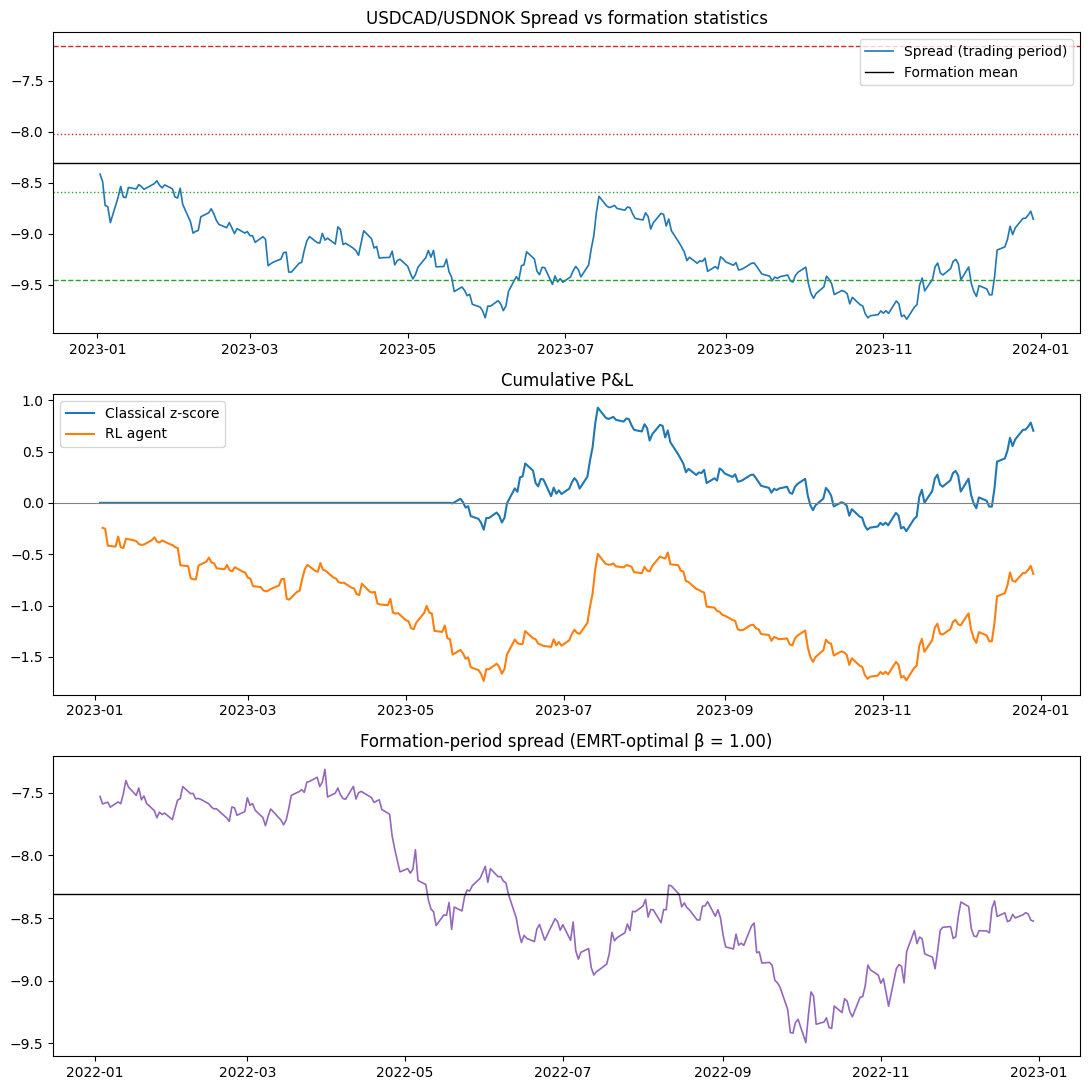

In [16]:
# Visualise the cointegrated pair results
emrt_c = cointegrated_results["emrt_result"]
spread_trading_c = cointegrated_results["trading_spread"]
mu_f_c, sd_f_c = emrt_c["spread_mean"], emrt_c["spread_std"]

fig, axes = plt.subplots(3, 1, figsize=(11, 11))

# 1. Trading-period spread
ax = axes[0]
ax.plot(spread_trading_c.index, spread_trading_c.values, lw=1.2, label="Spread (trading period)")
ax.axhline(mu_f_c, color="black", lw=1, label="Formation mean")
for m, ls in [(2.0, "--"), (0.5, ":")]:
    ax.axhline(mu_f_c + m * sd_f_c, color="tab:red", ls=ls, lw=1)
    ax.axhline(mu_f_c - m * sd_f_c, color="tab:green", ls=ls, lw=1)
ax.set_title("USDCAD/USDNOK Spread vs formation statistics")
ax.legend(loc="best")

# 2. Cumulative P&L
ax = axes[1]
classical_cum_c = cointegrated_results["classical_pnl"].cumsum()
rl_cum_c = cointegrated_results["rl_pnl"].reset_index(drop=True).cumsum()
ax.plot(classical_cum_c.index, classical_cum_c.values, label="Classical z-score")
rl_dates_c = spread_trading_c.index[-len(rl_cum_c):]
ax.plot(rl_dates_c, rl_cum_c.values, label="RL agent")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Cumulative P&L")
ax.legend(loc="best")

# 3. Formation-period spread
ax = axes[2]
ax.plot(emrt_c["spread"].index, emrt_c["spread"].values, lw=1.2, color="tab:purple")
ax.axhline(mu_f_c, color="black", lw=1)
ax.set_title(f"Formation-period spread (EMRT-optimal \u03b2 = {emrt_c['beta']:.2f})")

plt.tight_layout()
plt.show()


In [17]:
print("=" * 60)
print("Running Experiment with EUR/USD vs GBP/USD")
print("=" * 60)
print()

eur_gbp_results = run_fx_pairs_backtest(
    ticker1          = "EURUSD=X",
    ticker2          = "GBPUSD=X",
    formation_start  = "2022-01-01",
    formation_end    = "2022-12-31",
    trading_start    = "2023-01-01",
    trading_end      = "2023-12-31",
)

Running Experiment with EUR/USD vs GBP/USD

Cointegration p-value : 0.2483
Cointegrated          : False
Half-life             : 11.0 days

Optimal hedge ratio (EMRT): 0.5500
EMRT                      : 3.50 days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : -0.047
Classical Max DD : -2.55%
RL Agent Sharpe  : 0.145
RL Agent Max DD  : -2.81%


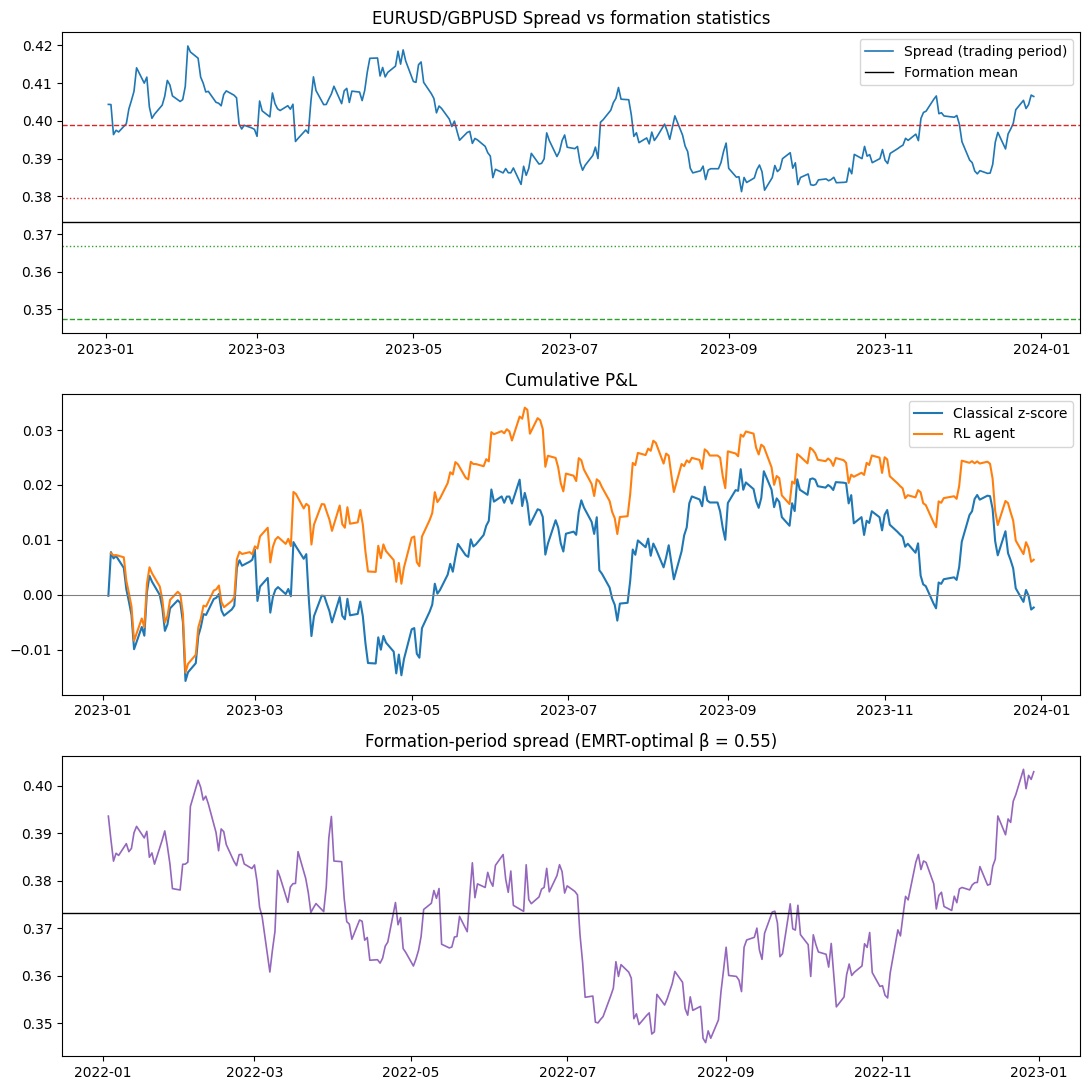

In [18]:
# Visualise the EUR/USD vs GBP/USD results
emrt_eg = eur_gbp_results["emrt_result"]
spread_trading_eg = eur_gbp_results["trading_spread"]
mu_f_eg, sd_f_eg = emrt_eg["spread_mean"], emrt_eg["spread_std"]

fig, axes = plt.subplots(3, 1, figsize=(11, 11))

# 1. Trading-period spread
ax = axes[0]
ax.plot(spread_trading_eg.index, spread_trading_eg.values, lw=1.2, label="Spread (trading period)")
ax.axhline(mu_f_eg, color="black", lw=1, label="Formation mean")
for m, ls in [(2.0, "--"), (0.5, ":")]:
    ax.axhline(mu_f_eg + m * sd_f_eg, color="tab:red", ls=ls, lw=1)
    ax.axhline(mu_f_eg - m * sd_f_eg, color="tab:green", ls=ls, lw=1)
ax.set_title("EURUSD/GBPUSD Spread vs formation statistics")
ax.legend(loc="best")

# 2. Cumulative P&L
ax = axes[1]
classical_cum_eg = eur_gbp_results["classical_pnl"].cumsum()
rl_cum_eg = eur_gbp_results["rl_pnl"].reset_index(drop=True).cumsum()
ax.plot(classical_cum_eg.index, classical_cum_eg.values, label="Classical z-score")
rl_dates_eg = spread_trading_eg.index[-len(rl_cum_eg):]
ax.plot(rl_dates_eg, rl_cum_eg.values, label="RL agent")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Cumulative P&L")
ax.legend(loc="best")

# 3. Formation-period spread
ax = axes[2]
ax.plot(emrt_eg["spread"].index, emrt_eg["spread"].values, lw=1.2, color="tab:purple")
ax.axhline(mu_f_eg, color="black", lw=1)
ax.set_title(f"Formation-period spread (EMRT-optimal \u03b2 = {emrt_eg['beta']:.2f})")

plt.tight_layout()
plt.show()

In [19]:
print('=' * 60)
print('Running Updated Experiments with the Mean-Shift Corrected Agent')
print('=' * 60)

print('\n>>> 1. AUD/USD vs NZD/USD')
results = run_fx_pairs_backtest(
    ticker1          = 'AUDUSD=X',
    ticker2          = 'NZDUSD=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

print('\n>>> 2. USD/CAD vs USD/NOK')
cointegrated_results = run_fx_pairs_backtest(
    ticker1          = 'USDCAD=X',
    ticker2          = 'USDNOK=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

print('\n>>> 3. EUR/USD vs GBP/USD')
eur_gbp_results = run_fx_pairs_backtest(
    ticker1          = 'EURUSD=X',
    ticker2          = 'GBPUSD=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

Running Updated Experiments with the Mean-Shift Corrected Agent

>>> 1. AUD/USD vs NZD/USD
Cointegration p-value : 0.7069
Cointegrated          : False
Half-life             : 25.2 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.000
Classical Max DD : 0.00%
RL Agent Sharpe  : 0.907
RL Agent Max DD  : -2.02%

>>> 2. USD/CAD vs USD/NOK
Cointegration p-value : 0.9551
Cointegrated          : False
Half-life             : 51.8 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.689
Classical Max DD : -74.46%
RL Agent Sharpe  : -1.704
RL Agent Max DD  : -89.67%

>>> 3. EUR/USD vs GBP/USD
Cointegration p-value : 0.2483
Cointegrated          : False
Half-life             : 11.0 days

Optimal hedge ratio (EMRT): 0.5500
EMRT                      : 3.50 days

Tra

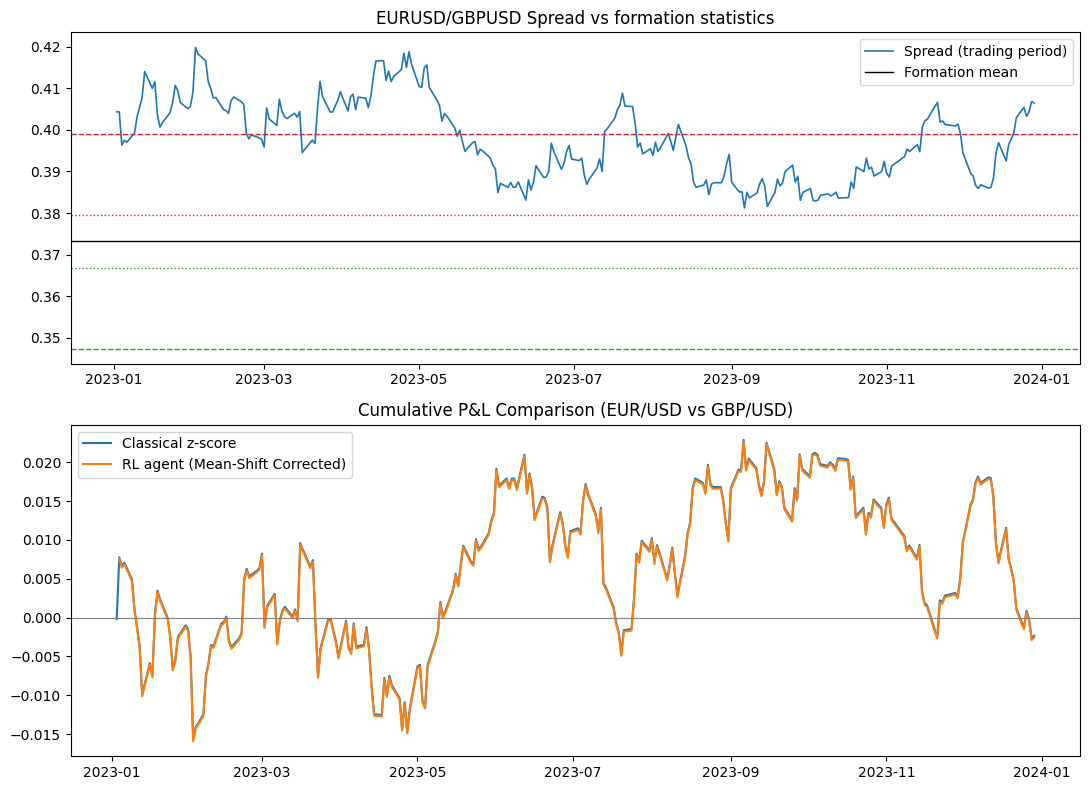

In [20]:
# Visualize the corrected agent performance on EUR/USD vs GBP/USD
emrt_eg = eur_gbp_results['emrt_result']
spread_trading_eg = eur_gbp_results['trading_spread']
mu_f_eg, sd_f_eg = emrt_eg['spread_mean'], emrt_eg['spread_std']

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# 1. Trading-period spread
ax = axes[0]
ax.plot(spread_trading_eg.index, spread_trading_eg.values, lw=1.2, label='Spread (trading period)')
ax.axhline(mu_f_eg, color='black', lw=1, label='Formation mean')
for m, ls in [(2.0, '--'), (0.5, ':')]:
    ax.axhline(mu_f_eg + m * sd_f_eg, color='tab:red', ls=ls, lw=1)
    ax.axhline(mu_f_eg - m * sd_f_eg, color='tab:green', ls=ls, lw=1)
ax.set_title('EURUSD/GBPUSD Spread vs formation statistics')
ax.legend(loc='best')

# 2. Cumulative P&L
ax = axes[1]
classical_cum_eg = eur_gbp_results['classical_pnl'].cumsum()
rl_cum_eg = eur_gbp_results['rl_pnl'].reset_index(drop=True).cumsum()
ax.plot(classical_cum_eg.index, classical_cum_eg.values, label='Classical z-score')
rl_dates_eg = spread_trading_eg.index[-len(rl_cum_eg):]
ax.plot(rl_dates_eg, rl_cum_eg.values, label='RL agent (Mean-Shift Corrected)')
ax.axhline(0, color='grey', lw=0.8)
ax.set_title('Cumulative P&L Comparison (EUR/USD vs GBP/USD)')
ax.legend(loc='best')

plt.tight_layout()
plt.show()

In [21]:
# Run the updated experiments with the active z-score + trend RL Agent
print('=' * 60)
print('Running Active Experiments with the Mean-Shift Corrected Agent')
print('=' * 60)

print('\n>>> 1. AUD/USD vs NZD/USD')
results = run_fx_pairs_backtest(
    ticker1          = 'AUDUSD=X',
    ticker2          = 'NZDUSD=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

print('\n>>> 2. USD/CAD vs USD/NOK')
cointegrated_results = run_fx_pairs_backtest(
    ticker1          = 'USDCAD=X',
    ticker2          = 'USDNOK=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

print('\n>>> 3. EUR/USD vs GBP/USD')
eur_gbp_results = run_fx_pairs_backtest(
    ticker1          = 'EURUSD=X',
    ticker2          = 'GBPUSD=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

Running Active Experiments with the Mean-Shift Corrected Agent

>>> 1. AUD/USD vs NZD/USD
Cointegration p-value : 0.7069
Cointegrated          : False
Half-life             : 25.2 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.000
Classical Max DD : 0.00%
RL Agent Sharpe  : 1.384
RL Agent Max DD  : -1.78%

>>> 2. USD/CAD vs USD/NOK
Cointegration p-value : 0.9551
Cointegrated          : False
Half-life             : 51.8 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.689
Classical Max DD : -74.46%
RL Agent Sharpe  : -0.638
RL Agent Max DD  : -90.76%

>>> 3. EUR/USD vs GBP/USD
Cointegration p-value : 0.2483
Cointegrated          : False
Half-life             : 11.0 days

Optimal hedge ratio (EMRT): 0.5500
EMRT                      : 3.50 days

Trai

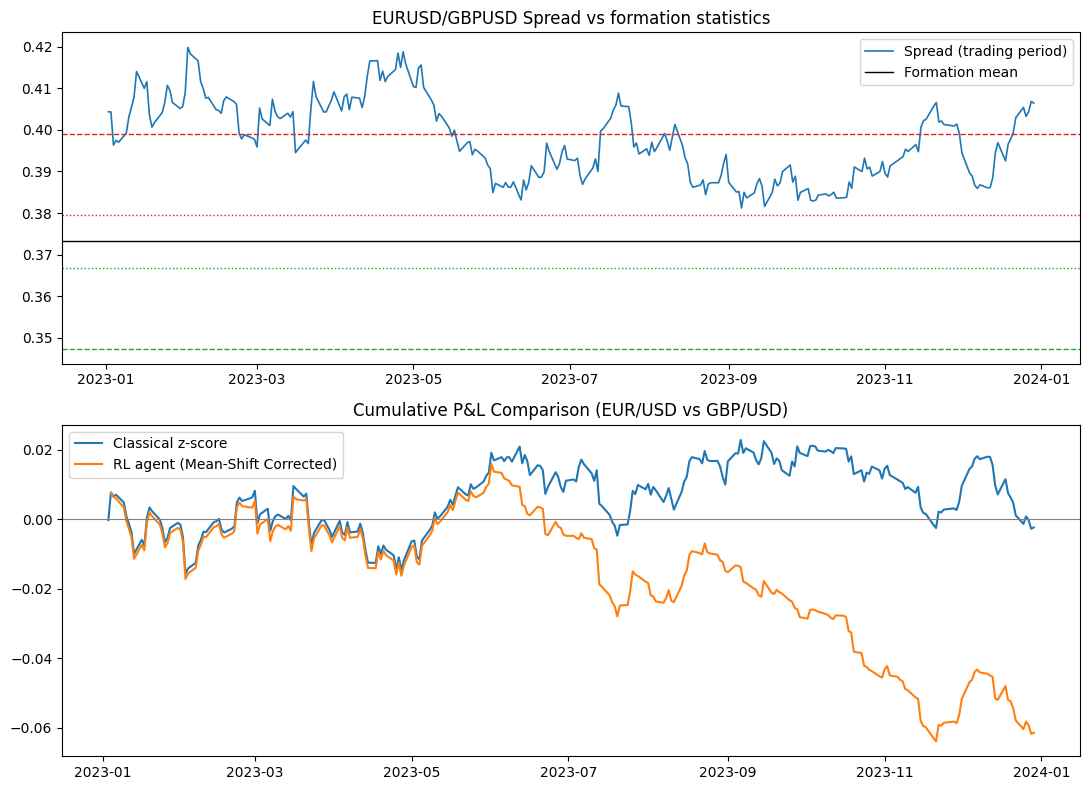

In [22]:
# Visualize the corrected agent performance on EUR/USD vs GBP/USD
emrt_eg = eur_gbp_results['emrt_result']
spread_trading_eg = eur_gbp_results['trading_spread']
mu_f_eg, sd_f_eg = emrt_eg['spread_mean'], emrt_eg['spread_std']

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# 1. Trading-period spread
ax = axes[0]
ax.plot(spread_trading_eg.index, spread_trading_eg.values, lw=1.2, label='Spread (trading period)')
ax.axhline(mu_f_eg, color='black', lw=1, label='Formation mean')
for m, ls in [(2.0, '--'), (0.5, ':')]:
    ax.axhline(mu_f_eg + m * sd_f_eg, color='tab:red', ls=ls, lw=1)
    ax.axhline(mu_f_eg - m * sd_f_eg, color='tab:green', ls=ls, lw=1)
ax.set_title('EURUSD/GBPUSD Spread vs formation statistics')
ax.legend(loc='best')

# 2. Cumulative P&L
ax = axes[1]
classical_cum_eg = eur_gbp_results['classical_pnl'].cumsum()
rl_cum_eg = eur_gbp_results['rl_pnl'].reset_index(drop=True).cumsum()
ax.plot(classical_cum_eg.index, classical_cum_eg.values, label='Classical z-score')
rl_dates_eg = spread_trading_eg.index[-len(rl_cum_eg):]
ax.plot(rl_dates_eg, rl_cum_eg.values, label='RL agent (Mean-Shift Corrected)')
ax.axhline(0, color='grey', lw=0.8)
ax.set_title('Cumulative P&L Comparison (EUR/USD vs GBP/USD)')
ax.legend(loc='best')

plt.tight_layout()
plt.show()

In [23]:
# Execute the updated backtests with short-selling enabled
print('=' * 60)
print('Running Short-Selling Enabled Experiments')
print('=' * 60)

print('\n>>> 1. AUD/USD vs NZD/USD')
results = run_fx_pairs_backtest(
    ticker1          = 'AUDUSD=X',
    ticker2          = 'NZDUSD=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

print('\n>>> 2. USD/CAD vs USD/NOK')
cointegrated_results = run_fx_pairs_backtest(
    ticker1          = 'USDCAD=X',
    ticker2          = 'USDNOK=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

print('\n>>> 3. EUR/USD vs GBP/USD')
eur_gbp_results = run_fx_pairs_backtest(
    ticker1          = 'EURUSD=X',
    ticker2          = 'GBPUSD=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

Running Short-Selling Enabled Experiments

>>> 1. AUD/USD vs NZD/USD
Cointegration p-value : 0.7069
Cointegrated          : False
Half-life             : 25.2 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.000
Classical Max DD : 0.00%
RL Agent Sharpe  : 0.697
RL Agent Max DD  : -2.02%

>>> 2. USD/CAD vs USD/NOK
Cointegration p-value : 0.9551
Cointegrated          : False
Half-life             : 51.8 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.689
Classical Max DD : -74.46%
RL Agent Sharpe  : -0.283
RL Agent Max DD  : -86.02%

>>> 3. EUR/USD vs GBP/USD
Cointegration p-value : 0.2483
Cointegrated          : False
Half-life             : 11.0 days

Optimal hedge ratio (EMRT): 0.5500
EMRT                      : 3.50 days

Training RL agent on simu

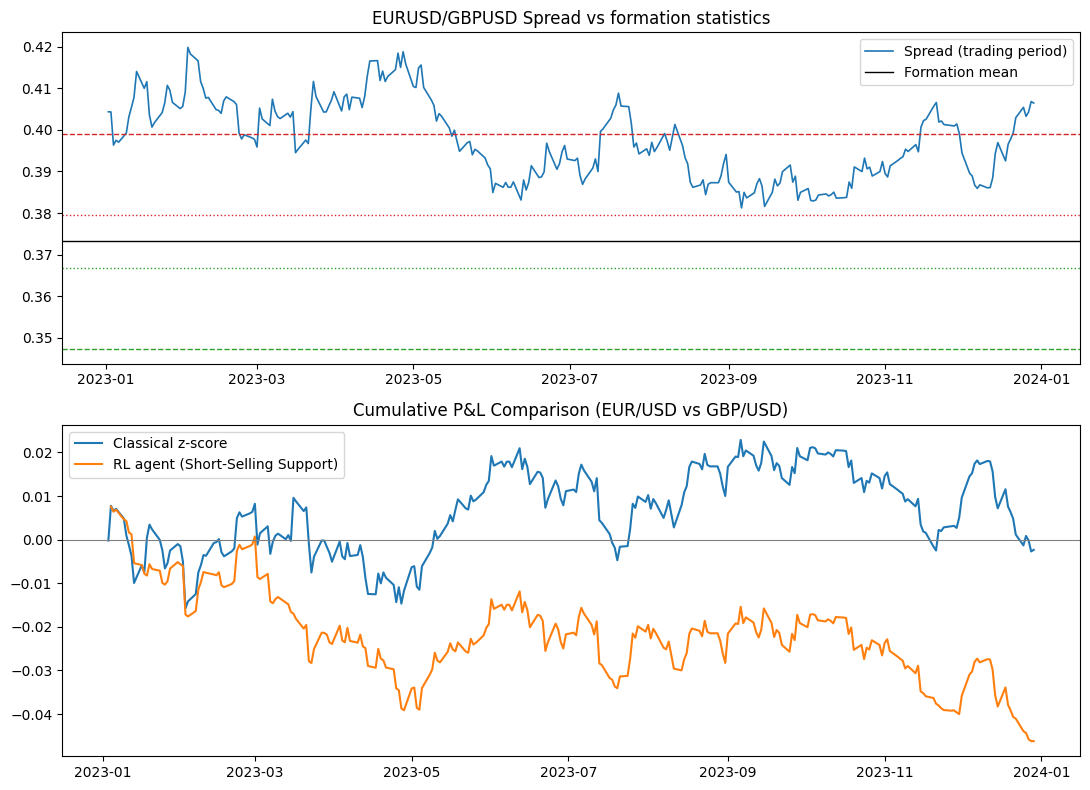

In [24]:
# Visualize the new performance on EUR/USD vs GBP/USD
emrt_eg = eur_gbp_results['emrt_result']
spread_trading_eg = eur_gbp_results['trading_spread']
mu_f_eg, sd_f_eg = emrt_eg['spread_mean'], emrt_eg['spread_std']

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# 1. Trading-period spread
ax = axes[0]
ax.plot(spread_trading_eg.index, spread_trading_eg.values, lw=1.2, label='Spread (trading period)')
ax.axhline(mu_f_eg, color='black', lw=1, label='Formation mean')
for m, ls in [(2.0, '--'), (0.5, ':')]:
    ax.axhline(mu_f_eg + m * sd_f_eg, color='tab:red', ls=ls, lw=1)
    ax.axhline(mu_f_eg - m * sd_f_eg, color='tab:green', ls=ls, lw=1)
ax.set_title('EURUSD/GBPUSD Spread vs formation statistics')
ax.legend(loc='best')

# 2. Cumulative P&L
ax = axes[1]
classical_cum_eg = eur_gbp_results['classical_pnl'].cumsum()
rl_cum_eg = eur_gbp_results['rl_pnl'].reset_index(drop=True).cumsum()
ax.plot(classical_cum_eg.index, classical_cum_eg.values, label='Classical z-score')
rl_dates_eg = spread_trading_eg.index[-len(rl_cum_eg):]
ax.plot(rl_dates_eg, rl_cum_eg.values, label='RL agent (Short-Selling Support)')
ax.axhline(0, color='grey', lw=0.8)
ax.set_title('Cumulative P&L Comparison (EUR/USD vs GBP/USD)')
ax.legend(loc='best')

plt.tight_layout()
plt.show()

In [33]:
print('=' * 60)
print('Running Backtests to Verify Active Trading & Store Trained Agents')
print('=' * 60)

# Run the updated backtest on our target pairs using the modified function
results_aud_nzd = run_fx_pairs_backtest(
    ticker1          = 'AUDUSD=X',
    ticker2          = 'NZDUSD=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

results_usd_cad = run_fx_pairs_backtest(
    ticker1          = 'USDCAD=X',
    ticker2          = 'USDNOK=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

results_eur_gbp = run_fx_pairs_backtest(
    ticker1          = 'EURUSD=X',
    ticker2          = 'GBPUSD=X',
    formation_start  = '2022-01-01',
    formation_end    = '2022-12-31',
    trading_start    = '2023-01-01',
    trading_end      = '2023-12-31',
)

Running Backtests to Verify Active Trading & Store Trained Agents
Cointegration p-value : 0.7069
Cointegrated          : False
Half-life             : 25.2 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.000
Classical Max DD : 0.00%
RL Agent Sharpe  : 0.012
RL Agent Max DD  : -3.26%
Cointegration p-value : 0.9551
Cointegrated          : False
Half-life             : 51.8 days

Optimal hedge ratio (EMRT): 1.0000
EMRT                      : inf days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sharpe : 0.689
Classical Max DD : -74.46%
RL Agent Sharpe  : -0.283
RL Agent Max DD  : -86.02%
Cointegration p-value : 0.2483
Cointegrated          : False
Half-life             : 11.0 days

Optimal hedge ratio (EMRT): 0.5500
EMRT                      : 3.50 days

Training RL agent on simulated paths...

--- Performance Summary ---
Classical Sha

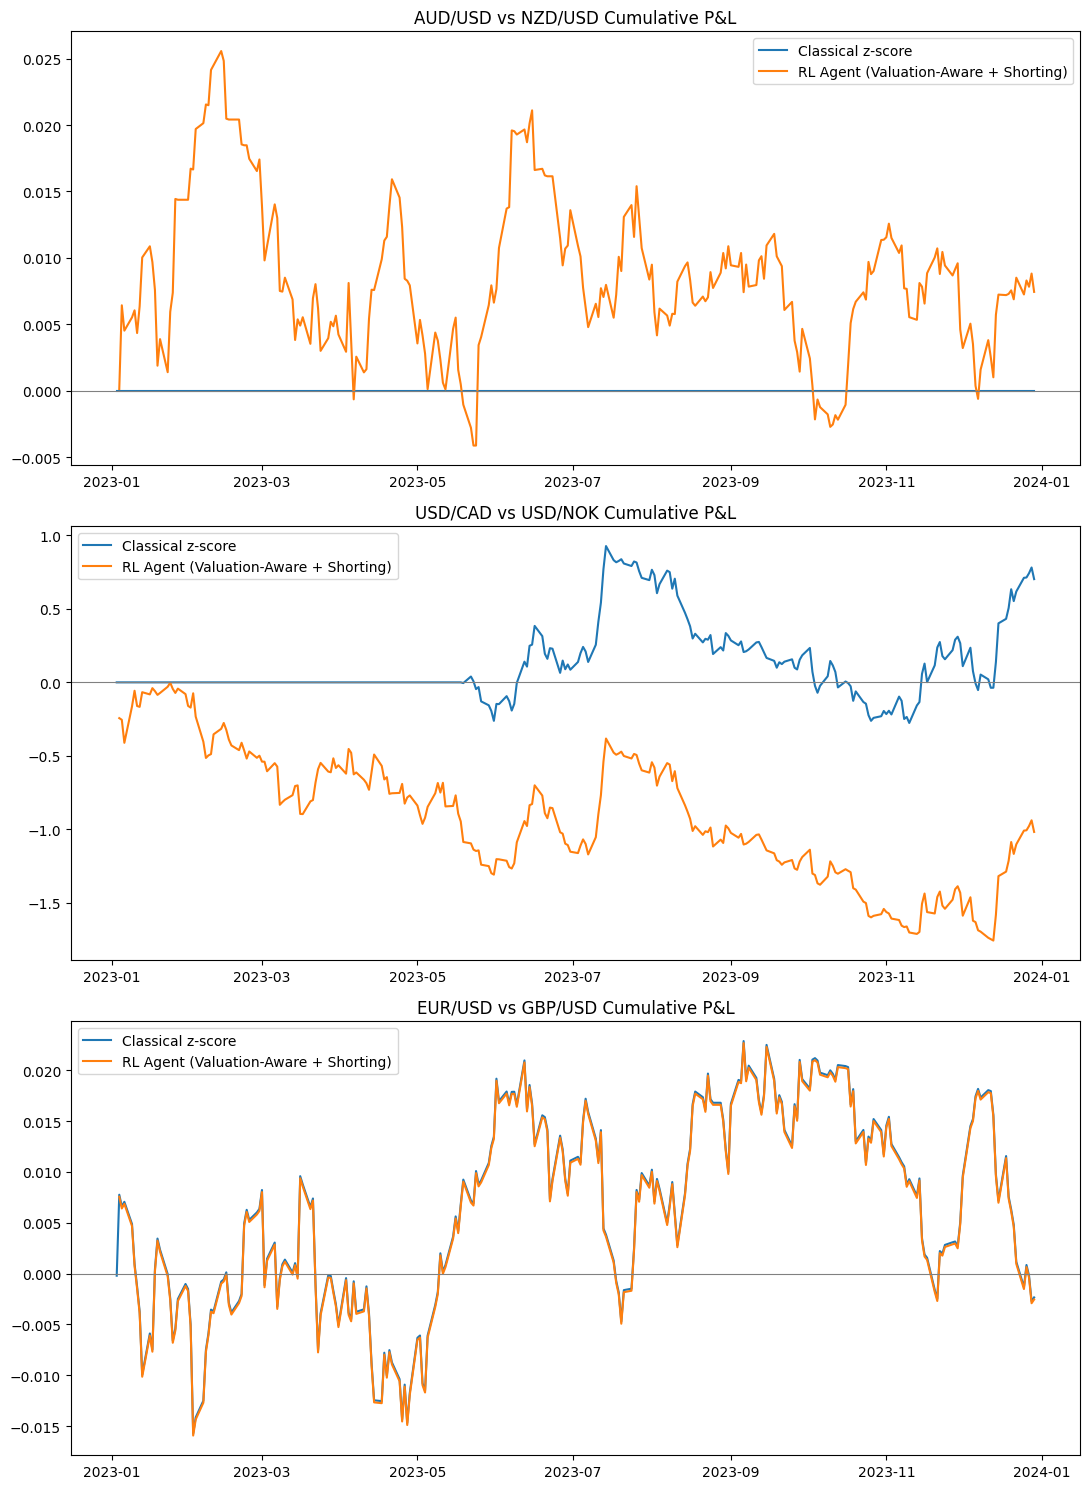

In [26]:
# Plot the updated performance curves to verify active trading visually
fig, axes = plt.subplots(3, 1, figsize=(11, 15))

# AUD/USD vs NZD/USD
ax = axes[0]
ax.plot(results_aud_nzd['classical_pnl'].cumsum().index, results_aud_nzd['classical_pnl'].cumsum().values, label='Classical z-score')
rl_cum_aud = results_aud_nzd['rl_pnl'].cumsum()
rl_dates_aud = results_aud_nzd['trading_spread'].index[-len(rl_cum_aud):]
ax.plot(rl_dates_aud, rl_cum_aud.values, label='RL Agent (Valuation-Aware + Shorting)')
ax.axhline(0, color='grey', lw=0.8)
ax.set_title('AUD/USD vs NZD/USD Cumulative P&L')
ax.legend(loc='best')

# USD/CAD vs USD/NOK
ax = axes[1]
ax.plot(results_usd_cad['classical_pnl'].cumsum().index, results_usd_cad['classical_pnl'].cumsum().values, label='Classical z-score')
rl_cum_cad = results_usd_cad['rl_pnl'].cumsum()
rl_dates_cad = results_usd_cad['trading_spread'].index[-len(rl_cum_cad):]
ax.plot(rl_dates_cad, rl_cum_cad.values, label='RL Agent (Valuation-Aware + Shorting)')
ax.axhline(0, color='grey', lw=0.8)
ax.set_title('USD/CAD vs USD/NOK Cumulative P&L')
ax.legend(loc='best')

# EUR/USD vs GBP/USD
ax = axes[2]
ax.plot(results_eur_gbp['classical_pnl'].cumsum().index, results_eur_gbp['classical_pnl'].cumsum().values, label='Classical z-score')
rl_cum_eur = results_eur_gbp['rl_pnl'].cumsum()
rl_dates_eur = results_eur_gbp['trading_spread'].index[-len(rl_cum_eur):]
ax.plot(rl_dates_eur, rl_cum_eur.values, label='RL Agent (Valuation-Aware + Shorting)')
ax.axhline(0, color='grey', lw=0.8)
ax.set_title('EUR/USD vs GBP/USD Cumulative P&L')
ax.legend(loc='best')

plt.tight_layout()
plt.show()

## Visualise the results

Numbers alone hide a lot. Three quick plots:

1. The trading-period **spread** with the formation mean and ±2σ / ±0.5σ bands (the classical entry and exit levels).
2. **Cumulative P&L** for both strategies (in spread price units).
3. The EMRT-optimal spread over the formation period — does it look mean-reverting?

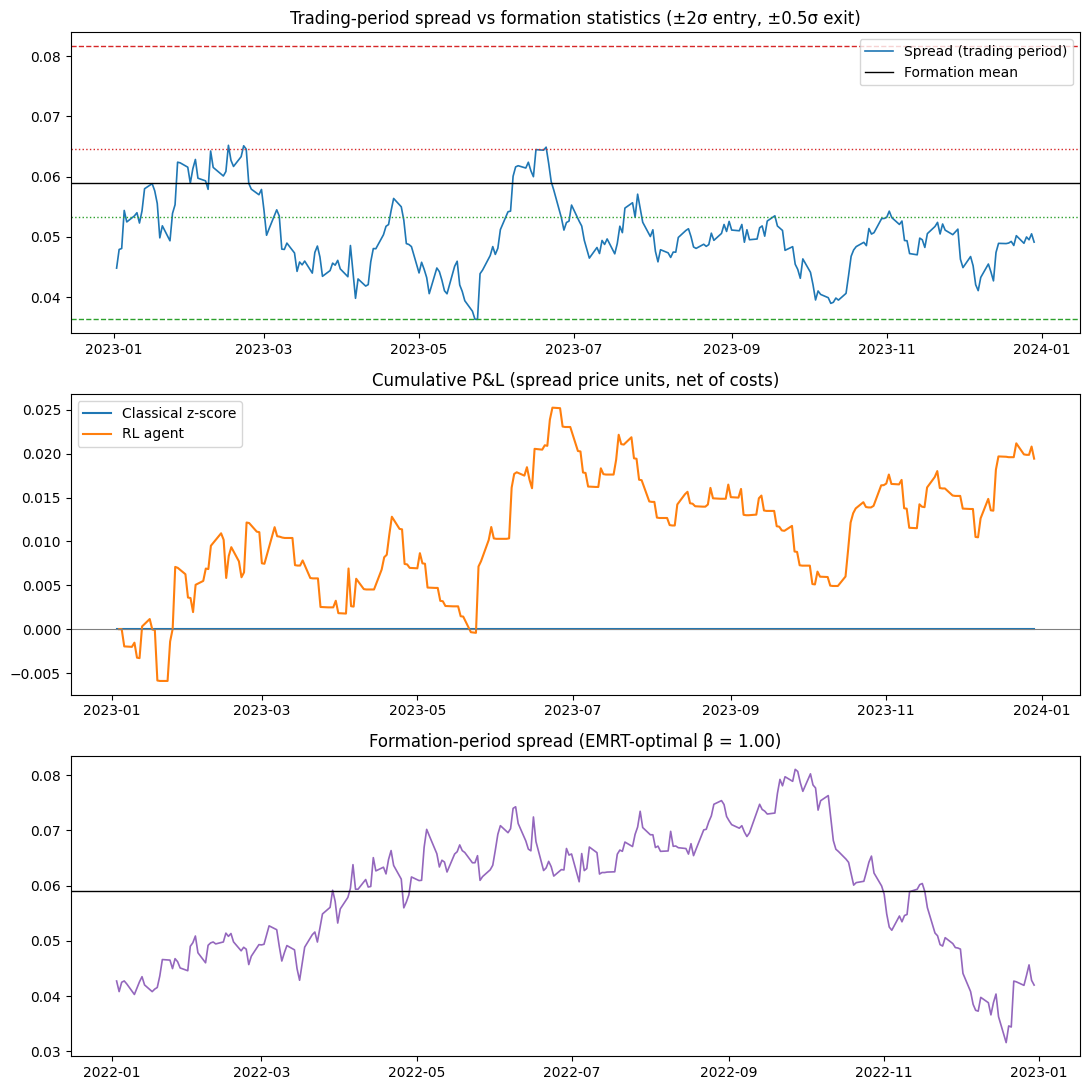

In [27]:
emrt = results["emrt_result"]
spread_trading = results["trading_spread"]
mu_f, sd_f = emrt["spread_mean"], emrt["spread_std"]

fig, axes = plt.subplots(3, 1, figsize=(11, 11))

# 1. Trading-period spread with z-score bands
ax = axes[0]
ax.plot(spread_trading.index, spread_trading.values, lw=1.2, label="Spread (trading period)")
ax.axhline(mu_f, color="black", lw=1, label="Formation mean")
for m, ls in [(2.0, "--"), (0.5, ":")]:
    ax.axhline(mu_f + m * sd_f, color="tab:red", ls=ls, lw=1)
    ax.axhline(mu_f - m * sd_f, color="tab:green", ls=ls, lw=1)
ax.set_title("Trading-period spread vs formation statistics (±2σ entry, ±0.5σ exit)")
ax.legend(loc="best")

# 2. Cumulative P&L
ax = axes[1]
classical_cum = results["classical_pnl"].cumsum()
rl_cum = results["rl_pnl"].reset_index(drop=True).cumsum()
ax.plot(classical_cum.index, classical_cum.values, label="Classical z-score")
# RL P&L has no date index; align it to the tail of the trading dates
rl_dates = spread_trading.index[-len(rl_cum):]
ax.plot(rl_dates, rl_cum.values, label="RL agent")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Cumulative P&L (spread price units, net of costs)")
ax.legend(loc="best")

# 3. Formation-period EMRT spread
ax = axes[2]
ax.plot(emrt["spread"].index, emrt["spread"].values, lw=1.2, color="tab:purple")
ax.axhline(mu_f, color="black", lw=1)
ax.set_title(f"Formation-period spread (EMRT-optimal β = {emrt['beta']:.2f})")

plt.tight_layout()
plt.show()

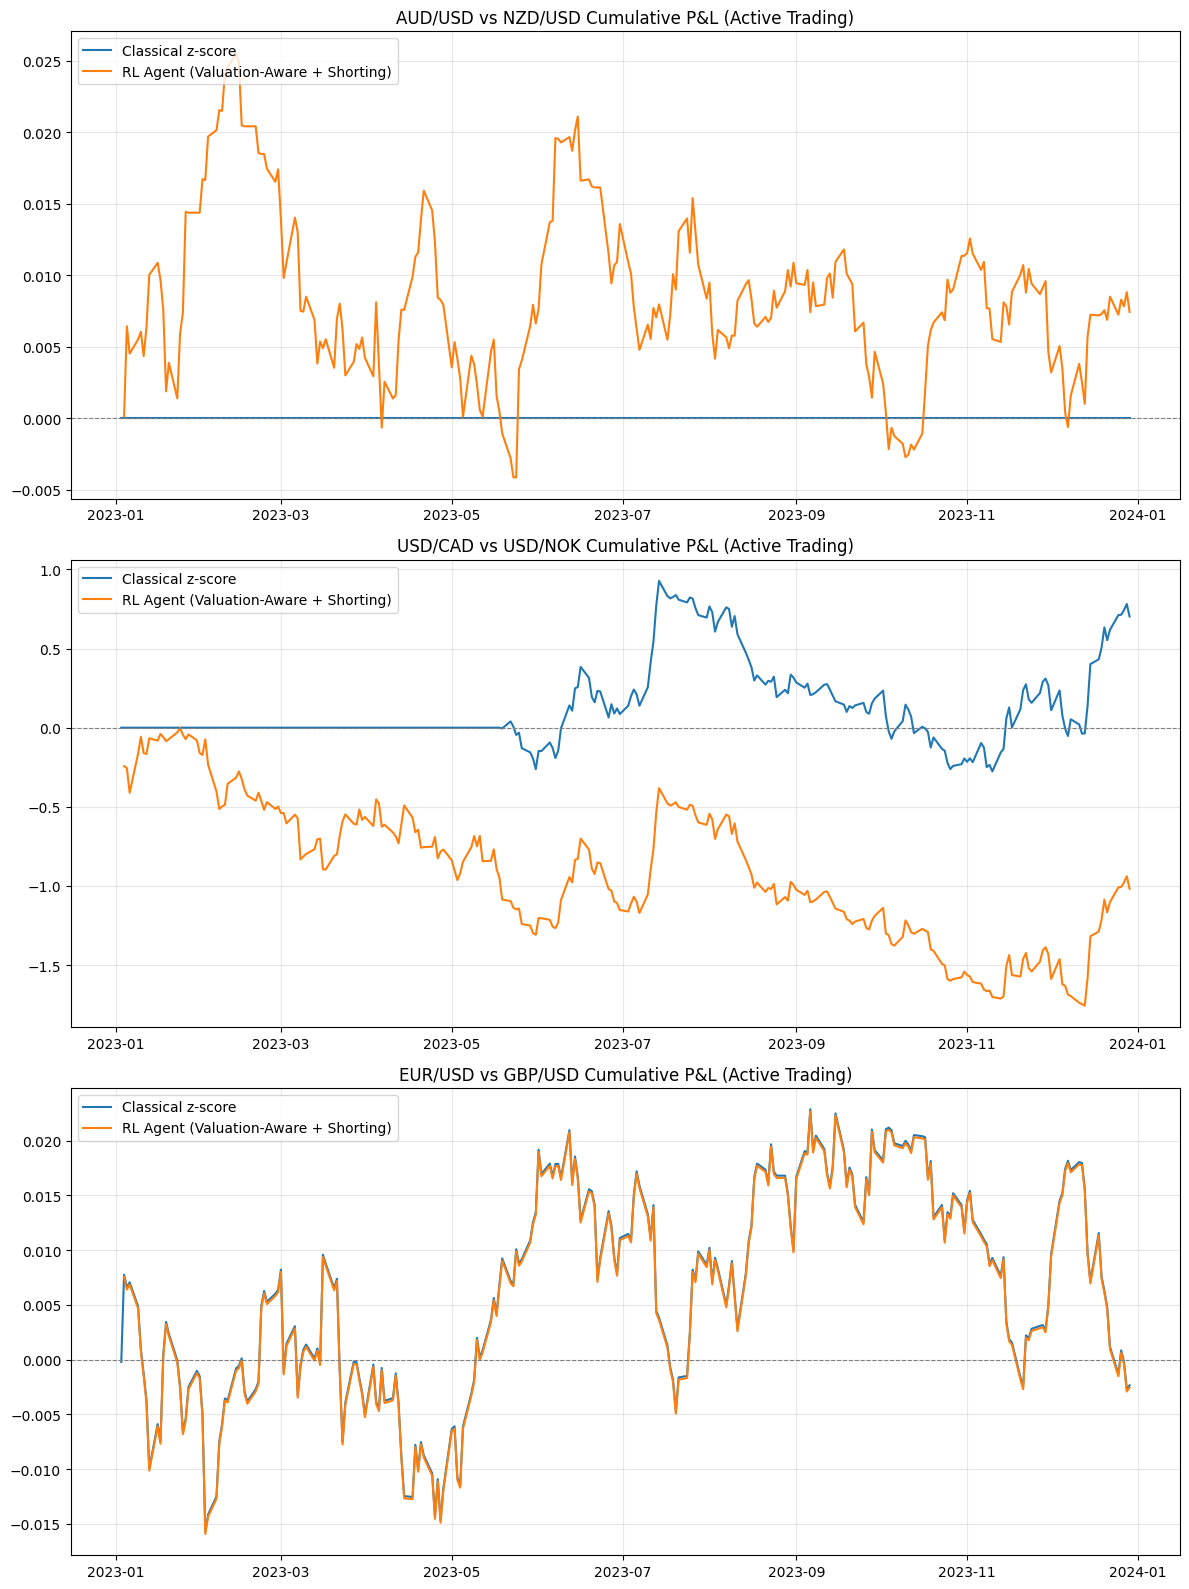

In [28]:
import matplotlib.pyplot as plt

# Set up the visualization for the updated active backtests
fig, axes = plt.subplots(3, 1, figsize=(12, 16))

# 1. AUD/USD vs NZD/USD
ax = axes[0]
classical_cum_aud = results_aud_nzd['classical_pnl'].cumsum()
rl_cum_aud = results_aud_nzd['rl_pnl'].cumsum()
# Align RL indices with trading dates
rl_dates_aud = results_aud_nzd['trading_spread'].index[-len(rl_cum_aud):]

ax.plot(classical_cum_aud.index, classical_cum_aud.values, label='Classical z-score', color='tab:blue')
ax.plot(rl_dates_aud, rl_cum_aud.values, label='RL Agent (Valuation-Aware + Shorting)', color='tab:orange')
ax.axhline(0, color='grey', linestyle='--', lw=0.8)
ax.set_title('AUD/USD vs NZD/USD Cumulative P&L (Active Trading)')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

# 2. USD/CAD vs USD/NOK
ax = axes[1]
classical_cum_cad = results_usd_cad['classical_pnl'].cumsum()
rl_cum_cad = results_usd_cad['rl_pnl'].cumsum()
rl_dates_cad = results_usd_cad['trading_spread'].index[-len(rl_cum_cad):]

ax.plot(classical_cum_cad.index, classical_cum_cad.values, label='Classical z-score', color='tab:blue')
ax.plot(rl_dates_cad, rl_cum_cad.values, label='RL Agent (Valuation-Aware + Shorting)', color='tab:orange')
ax.axhline(0, color='grey', linestyle='--', lw=0.8)
ax.set_title('USD/CAD vs USD/NOK Cumulative P&L (Active Trading)')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

# 3. EUR/USD vs GBP/USD
ax = axes[2]
classical_cum_eur = results_eur_gbp['classical_pnl'].cumsum()
rl_cum_eur = results_eur_gbp['rl_pnl'].cumsum()
rl_dates_eur = results_eur_gbp['trading_spread'].index[-len(rl_cum_eur):]

ax.plot(classical_cum_eur.index, classical_cum_eur.values, label='Classical z-score', color='tab:blue')
ax.plot(rl_dates_eur, rl_cum_eur.values, label='RL Agent (Valuation-Aware + Shorting)', color='tab:orange')
ax.axhline(0, color='grey', linestyle='--', lw=0.8)
ax.set_title('EUR/USD vs GBP/USD Cumulative P&L (Active Trading)')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## To inspect and visualize what the MeanReversionRLAgent from Strategy Lab #2

To inspect and visualize what the `MeanReversionRLAgent` from **Strategy Lab #2** actually learned during its synthetic Ornstein-Uhlenbeck (OU) pre-training, we can decode the base-4 state indices back into human-readable return regimes (e.g., `["-2", "-1", "+1", "+2"]`) and plot both:

1. **A Summary Policy Table:** Top states by action preference or Q-value spread (`max(Q) - second_max(Q)`), showing whether the agent favors **Short (`-1`)**, **Hold (`0`)**, or **Long (`+1`)** given its current position state (`Flat`, `Long`, `Short`).
2. **A Visual Policy & Q-Value Heatmap:** A clean side-by-side matrix showing the greedy action (`-1`, `0`, `+1`) and Q-value confidence/advantage across states and position modes.

---

### Inspecting & Visualizing the Learned Q-Table Policy

You can run this cell right after training `agent` (`agent.train_on_simulated_paths(...)`) in Strategy Lab #2:

In [35]:
# Extract the trained RL agent from the AUD/USD vs NZD/USD backtest results
agent = results_aud_nzd['agent']
print("Agent extracted successfully! You can now run the visualization cell below.")

Agent extracted successfully! You can now run the visualization cell below.


=== Top 12 Highest-Conviction Policy Rules | Current Position: Flat ===
 State_ID                                       Return_Pattern Greedy_Action  Q_Margin  Q_Short   Q_Hold   Q_Long
       11       z >= 2.0 (Deep Overbought) | Up/Flat (Trend +)    Short (-1)    6.7502 107.2483 100.4980  98.6325
       10          z >= 2.0 (Deep Overbought) | Down (Trend -)    Short (-1)    5.9717 107.5435 101.5718  98.6091
        1         z < -2.0 (Deep Oversold) | Up/Flat (Trend +)     Long (+1)    4.1653 101.1265 108.1495 112.3148
        8         0.5 <= z < 2.0 (Overbought) | Down (Trend -)    Short (-1)    3.4051  96.5359  93.1308  90.5080
        9      0.5 <= z < 2.0 (Overbought) | Up/Flat (Trend +)    Short (-1)    3.1845  96.7411  93.5566  90.5185
        0            z < -2.0 (Deep Oversold) | Down (Trend -)     Long (+1)    2.9497 101.6384 108.6040 111.5538
        2         -2.0 <= z < -0.5 (Oversold) | Down (Trend -)     Long (+1)    2.7126  93.6325  96.6032  99.3158
        3      -

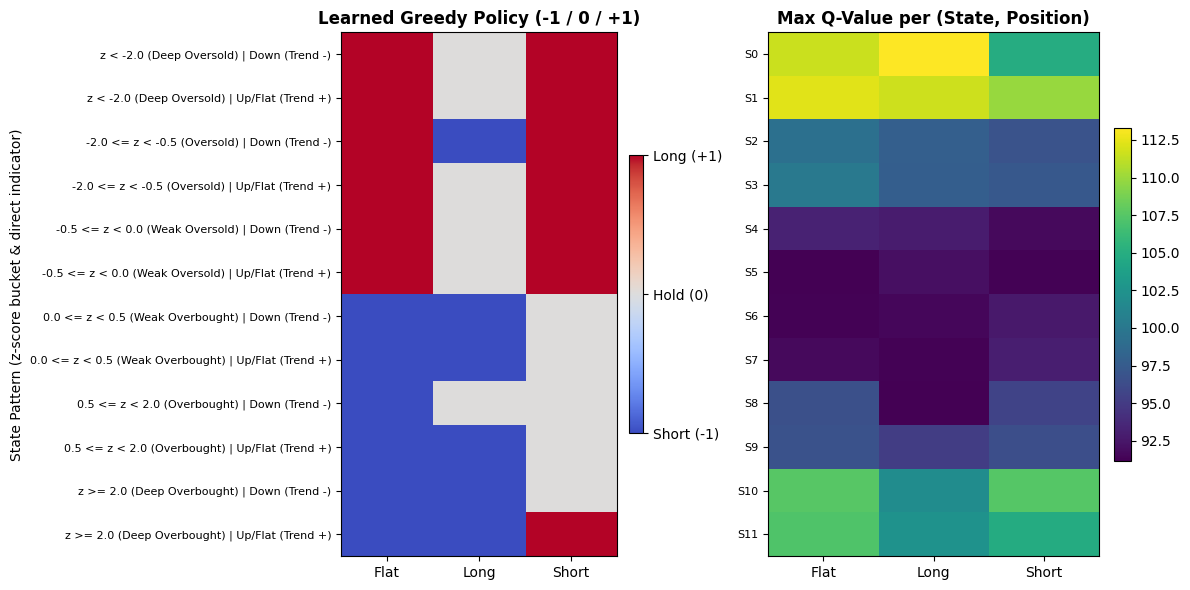

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ----------------------------------------------------------------------
# 1. Decoding Agent States into Readable Regimes
# ----------------------------------------------------------------------
Z_LEVELS = {
    0: "z < -2.0 (Deep Oversold)",
    1: "-2.0 <= z < -0.5 (Oversold)",
    2: "-0.5 <= z < 0.0 (Weak Oversold)",
    3: "0.0 <= z < 0.5 (Weak Overbought)",
    4: "0.5 <= z < 2.0 (Overbought)",
    5: "z >= 2.0 (Deep Overbought)"
}
DIR_LABELS = {0: "Down (Trend -)", 1: "Up/Flat (Trend +)"}
ACTION_LABELS = {0: "Short (-1)", 1: "Hold (0)", 2: "Long (+1)"}
POS_LABELS = {0: "Flat", 1: "Long", 2: "Short"}

def decode_state(state_idx: int, lookback: int = 1) -> str:
    """Converts the agent's actual encoded state index to a readable string."""
    level = state_idx // 2
    dir_bucket = state_idx % 2
    level_str = Z_LEVELS.get(level, f"Level {level}")
    dir_str = DIR_LABELS.get(dir_bucket, f"Dir {dir_bucket}")
    return f"{level_str} | {dir_str}"

def build_policy_dataframe(agent, pos_idx: int = 0) -> pd.DataFrame:
    """
    Extracts Q-values, greedy action, and Q-advantage (best minus runner-up)
    for all states under a given current position state (`pos_idx`).
    """
    rows = []
    for s in range(agent.n_states):
        q_row = agent.Q[s, pos_idx, :]
        best_idx = int(np.argmax(q_row))
        sorted_q = np.sort(q_row)
        q_margin = float(sorted_q[-1] - sorted_q[-2])

        rows.append({
            "State_ID": s,
            "Return_Pattern": decode_state(s, agent.lookback),
            "Q_Short": round(float(q_row[0]), 5),
            "Q_Hold": round(float(q_row[1]), 5),
            "Q_Long": round(float(q_row[2]), 5),
            "Greedy_Action": ACTION_LABELS[best_idx],
            "Action_Code": {-1: -1, 0: 0, 1: 1}[agent.action_map[best_idx]],
            "Q_Margin": round(q_margin, 5),
        })

    return pd.DataFrame(rows)

# ----------------------------------------------------------------------
# 2. Printing the Learned Policy Table
# ----------------------------------------------------------------------
def print_top_policy_rules(agent, pos_idx: int = 0, top_n: int = 12):
    """Prints the highest-conviction state-action rules for a position state."""
    df_pol = build_policy_dataframe(agent, pos_idx=pos_idx)
    df_ranked = df_pol.sort_values(by="Q_Margin", ascending=False).head(top_n)

    print(f"=== Top {top_n} Highest-Conviction Policy Rules | Current Position: {POS_LABELS[pos_idx]} ===")
    print(df_ranked[["State_ID", "Return_Pattern", "Greedy_Action", "Q_Margin", "Q_Short", "Q_Hold", "Q_Long"]].to_string(index=False))
    return df_pol

# ----------------------------------------------------------------------
# 3. Visualizing the Policy & Q-Value Matrices
# ----------------------------------------------------------------------
def plot_q_policy_map(agent):
    """
    Plots greedy actions (-1, 0, +1) and max Q-values across all states
    for each position regime (Flat, Long, Short).
    """
    n_pos = agent.Q.shape[1]
    state_labels = [decode_state(s, agent.lookback) for s in range(agent.n_states)]

    action_grid = np.zeros((agent.n_states, n_pos), dtype=int)
    max_q_grid = np.zeros((agent.n_states, n_pos), dtype=float)

    for s in range(agent.n_states):
        for p in range(n_pos):
            q_vals = agent.Q[s, p, :]
            best_a_idx = int(np.argmax(q_vals))
            action_grid[s, p] = agent.action_map[best_a_idx]
            max_q_grid[s, p] = float(np.max(q_vals))

    fig = plt.figure(figsize=(12, max(6, agent.n_states * 0.4)))
    gs = gridspec.GridSpec(1, 2, width_ratios=[1.0, 1.2], figure=fig)

    # Left panel: Greedy Action Map
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(action_grid, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
    ax1.set_title("Learned Greedy Policy (-1 / 0 / +1)", fontweight="bold")
    ax1.set_xticks(range(n_pos))
    ax1.set_xticklabels([POS_LABELS.get(p, f"Pos {p}") for p in range(n_pos)])
    ax1.set_yticks(range(agent.n_states))
    ax1.set_yticklabels(state_labels, fontsize=8)
    ax1.set_ylabel("State Pattern (z-score bucket & direct indicator)")
    cbar1 = plt.colorbar(im1, ax=ax1, ticks=[-1, 0, 1], fraction=0.046, pad=0.04)
    cbar1.ax.set_yticklabels(["Short (-1)", "Hold (0)", "Long (+1)"])

    # Right panel: Max Q-Value Heatmap
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(max_q_grid, aspect="auto", cmap="viridis")
    ax2.set_title("Max Q-Value per (State, Position)", fontweight="bold")
    ax2.set_xticks(range(n_pos))
    ax2.set_xticklabels([POS_LABELS.get(p, f"Pos {p}") for p in range(n_pos)])
    ax2.set_yticks(range(agent.n_states))
    ax2.set_yticklabels([f"S{s}" for s in range(agent.n_states)], fontsize=8)
    plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# --- Execution ---
try:
    df_flat_policy = print_top_policy_rules(agent, pos_idx=0, top_n=12)
    plot_q_policy_map(agent)
except NameError:
    print("Error: 'agent' is not defined. Please run cell 31gBQqj9PAq1 first to extract the agent.")

---

### How to Interpret What You See

* **High `Q_Margin` with Long (`+1`) after negative return steps (`-2`, `-1`):** Indicates the agent learned to buy mean-reverting pullbacks toward the OU equilibrium $\theta$.
* **Near-zero `Q_Margin` across rare states:** With `lookback = 4` ($4^4 = 256$ states), some extreme sequences are visited infrequently during pre-training—checking `Q_Margin` helps spot under-sampled states before live deployment.

## Experiments for you to try

This notebook is meant to be broken and extended. Some starting points, roughly from easy to ambitious:

**Easy**
- Swap the pair: `EURUSD=X` / `GBPUSD=X`, or `USDCAD=X` / `USDNOK=X`. Does the cointegration test still pass?
- Shift the formation and trading windows. How stable is the hedge ratio from year to year?
- Change the z-score thresholds (`entry_threshold`, `exit_threshold`) and the cost (`cost_bps`).

**Intermediate**
- Tune the agent: `lookback`, `k`, `alpha`, `gamma`, `epsilon`, `n_paths`, and the OU parameters `mu` and `sigma`. Try estimating `mu` and `sigma` from the formation-period spread rather than hard-coding them.
- Run the whole backtest across 20 random seeds and look at the *distribution* of RL Sharpe ratios, not a single draw.
- Make the EMRT parameter `C` data-driven, or add a stability check on the hedge ratio.

**Ambitious**
- Allow the agent to go **short** the spread (extend the position dimension of the Q-table to three values).
- Replace the Q-table with a small neural network (DQN) and compare.
- Run a rolling walk-forward: re-estimate $\beta$, re-train the agent and re-test every quarter.
- Report returns as a percentage of capital, and add a deflated Sharpe ratio to account for the number of configurations you tried.

## Known simplifications and limitations

These are real, and worth understanding before drawing conclusions from any single run:

1. **Small sample.** One year of daily data is ~250 observations. Sharpe ratios and drawdowns from one run are very noisy.
2. **Engle–Granger vs Johansen.** The cointegration function uses Engle–Granger (see the naming note in Phase 1).
3. **P&L in price units.** Both strategies report P&L in spread price units. The drawdown helper in the pipeline compounds those values as if they were fractional returns, so treat the reported max drawdown as indicative only; the Sharpe ratio is unaffected by this scaling.
4. **Simplified RL reward.** The training reward is a simple mean-reversion proxy, `action × (θ − X)`, minus costs — it is not the realised P&L of the position. The `hold` action always earns zero reward during training.
5. **Position indexing in the Q-update.** In `train_on_simulated_paths`, the Q-table is updated using the position *after* the action is applied, while the action was *selected* using the position *before* it. This is a modelling shortcut worth reviewing if you extend the agent.
6. **Percentage-return states on OU paths.** Spread returns are computed as $\Delta X / |X|$. If the spread mean $\theta$ is close to zero, these returns explode and the state discretisation degrades.
7. **Costs are stylised.** No bid/ask spread, no rollover/swap carry, no slippage, no execution delay, and the hedge legs are assumed tradable at the quoted close.
8. **In-sample selection of the pair.** The pair was chosen for illustration. Choosing pairs after seeing the results is a form of look-ahead bias.

<a id="risk-disclosure"></a>
## Risk disclosure

This notebook and the accompanying article are for **educational and research purposes only**. They are not investment advice, an offer, or a solicitation to buy or sell any financial instrument. Backtests are hypothetical, are built with hindsight, and do not account for all real-world frictions. Past performance does not predict future results. FX and leveraged products can lose more than the capital invested. The code is an **experimental prototype**, not production software, and is provided "as is" without warranty. Do your own research and consult a qualified professional before making any financial decision.

---
**Algorithmic Token · ENTER Invest** — [algorithmictoken.substack.com](https://algorithmictoken.substack.com)